In [1]:
VERSION = "1.0.1_sextractor"

# "1.0.1": "ellips gaussian + pixels_out",
# "1.0.2": "ellips uniform + pixels_out",
# "1.0.3": "ellips gaussian",
# hypercube + 40_000 + shear round 2 + 10 gal/patch + shear |0.06|

# lib

In [2]:
from pathlib import Path

from jax import numpy
from polars import DataFrame, read_csv
from tqdm import tqdm
from utils import load_and_slice_csv, ratio_angle_to_e1e2
from utils_plot import check_psf, final_results, histos, plot_sersic, plot_vignettes, print_fits

DATASET_DIR = Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid") / VERSION
PSF_DIR = Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid") / "PSF"

VERSION_DIR = Path("/net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR") / VERSION
IMAGES_DIR = VERSION_DIR / "IMAGES"
VIGNET_DIR = VERSION_DIR / "VIGNET"
RESULTS_DIR = VERSION_DIR / "RESULTS"
PLOTS_DIR = VERSION_DIR / "PLOTS"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# sersic (numerical stability?)

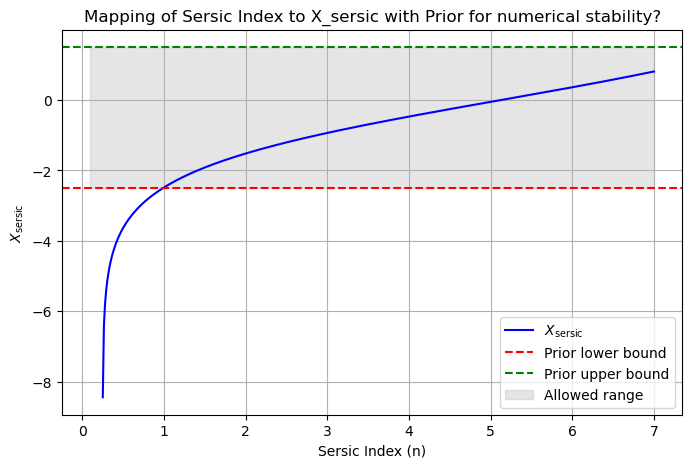

In [3]:
X_min, X_max = -2.5, 1.5
plot_sersic(X_min, X_max, PLOTS_DIR)
del X_min, X_max

# psf

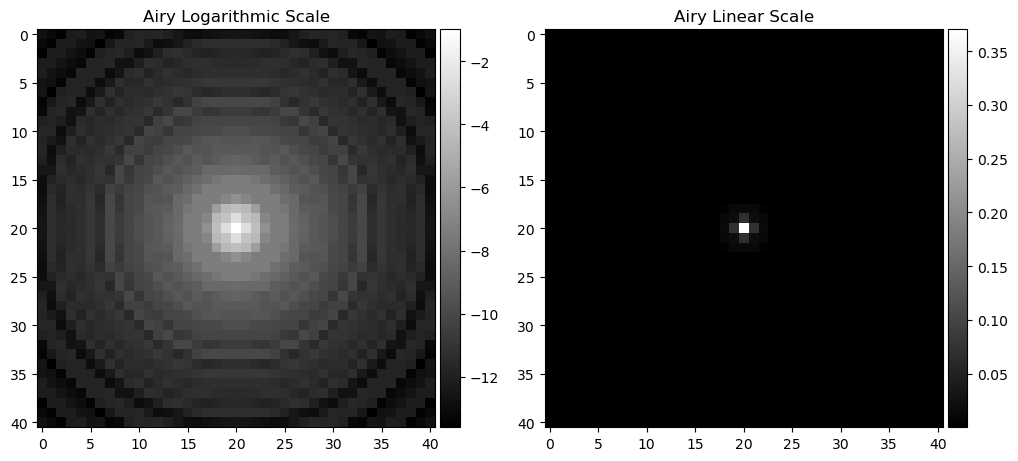

In [4]:
check_psf(PSF_DIR / "airy.psf.fits", PLOTS_DIR)

# images

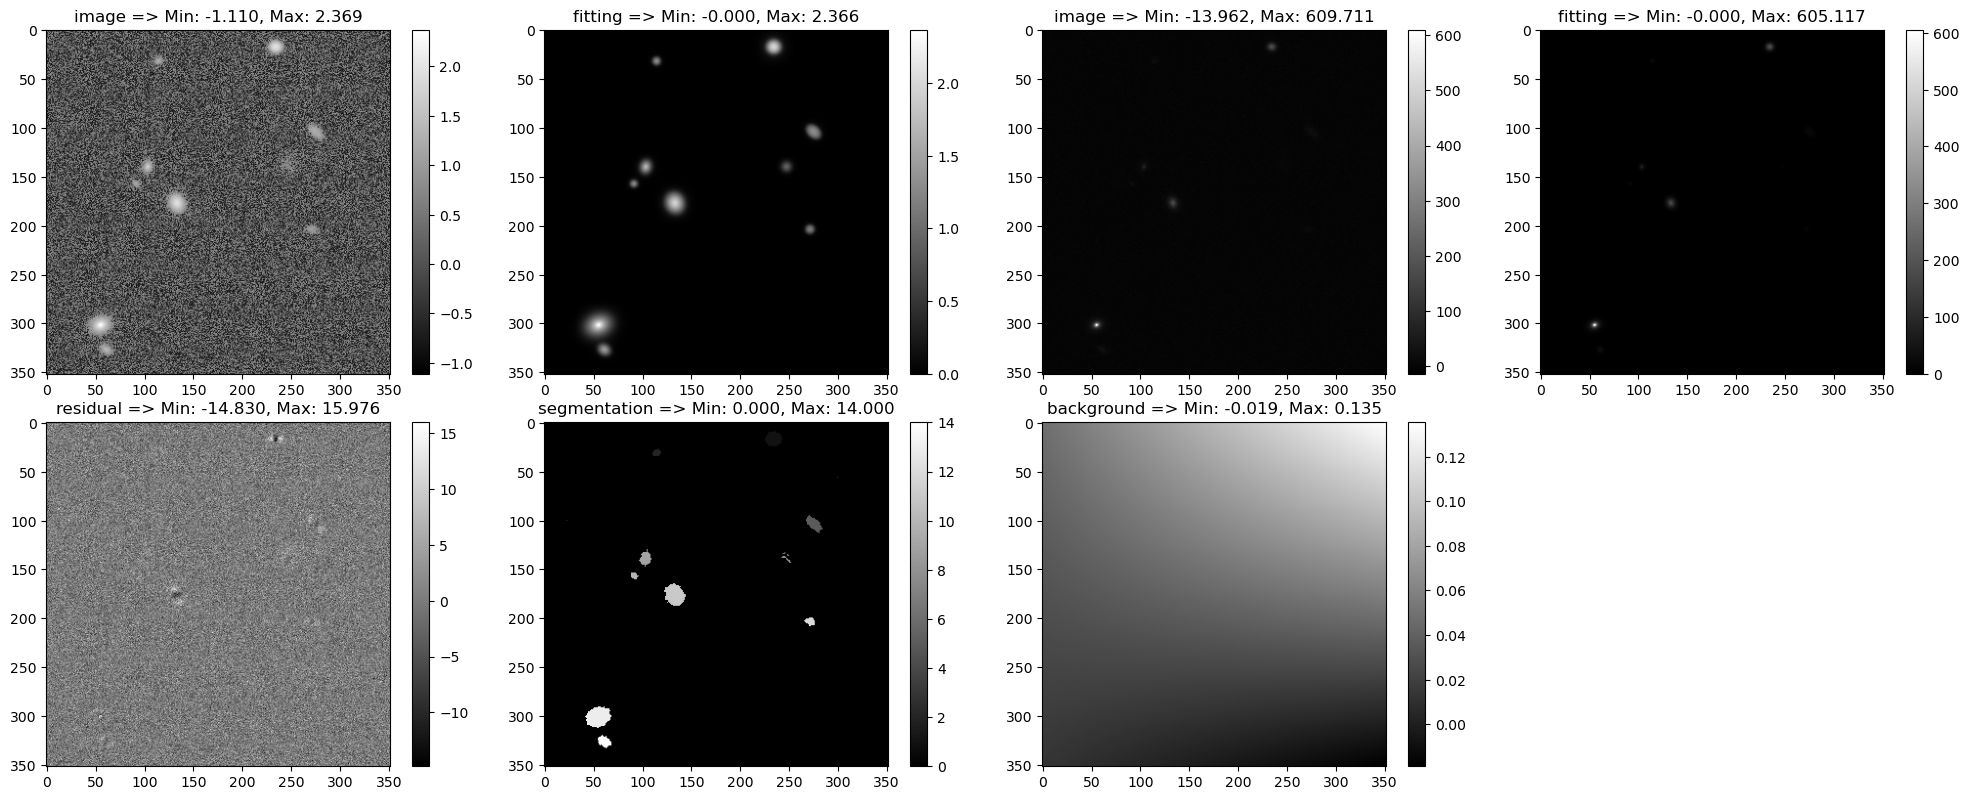

In [12]:
CHOICE = "simu_00005"

print_fits(
    [
        DATASET_DIR / CHOICE,
        IMAGES_DIR / f"fitting_{CHOICE}_1",
        DATASET_DIR / CHOICE,
        IMAGES_DIR / f"fitting_{CHOICE}_1",
        IMAGES_DIR / f"residual_{CHOICE}_1",
        IMAGES_DIR / f"segmentation_{CHOICE}",
        IMAGES_DIR / f"background_{CHOICE}",
    ],
    ["image", "fitting", "image", "fitting", "residual", "segmentation", "background"],
    PLOTS_DIR,
)

# vignettes

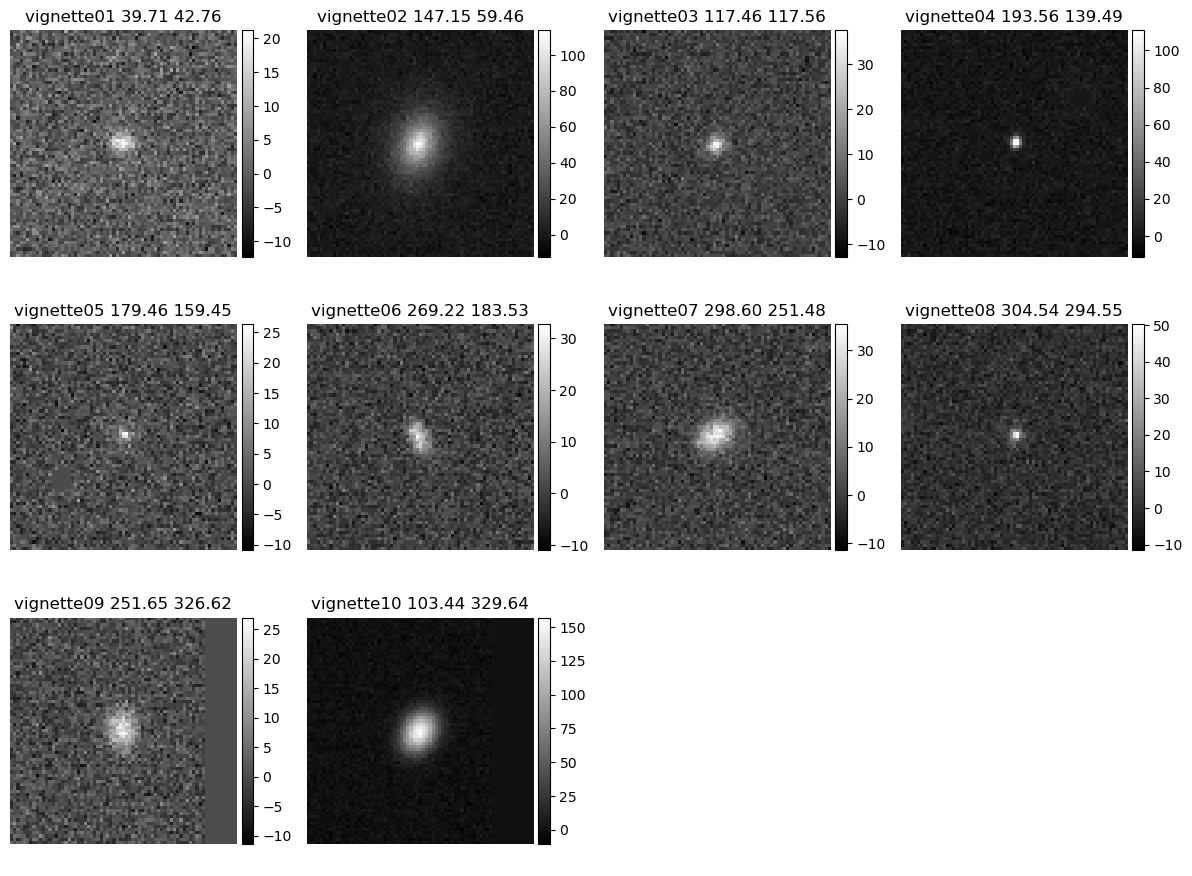

In [6]:
CHOICE = "simu_00001"

X = read_csv(f"{RESULTS_DIR / CHOICE}.csv")["x"]
Y = read_csv(f"{RESULTS_DIR / CHOICE}.csv")["y"]
VIGNETTES = sorted(list((VIGNET_DIR / CHOICE).glob("*.fits")))

plot_vignettes(VIGNETTES, X, Y, PLOTS_DIR)
del VIGNETTES, X, Y

# inference

In [7]:
file_path = VERSION_DIR / "pred_avg_ellipticies.csv"
RESULTS_FILES = sorted(list((RESULTS_DIR).glob("simu_*.csv")))
NB_TOTAL = len(RESULTS_FILES)

NB_FAKE_SEG = 0
avg_e1, avg_e2, recons_avg_e1, recons_avg_e2, gal_detect = [], [], [], [], []
for sample in tqdm(RESULTS_FILES, total=NB_TOTAL):
    df = read_csv(sample)
    gal_detect.append(df.shape[0])
    if df.shape[0] != 10:
        NB_FAKE_SEG += 1

    avg_e1.append(df["e1"].to_numpy().mean())
    avg_e2.append(df["e2"].to_numpy().mean())

    ratio = df["ratio"].to_numpy()
    angle = df["angle"].to_numpy()
    recons_e1, recons_e2 = ratio_angle_to_e1e2(ratio, angle)
    recons_avg_e1.append(recons_e1.mean())
    recons_avg_e2.append(recons_e2.mean())

# write res
DataFrame(
    {
        "avg_e1": avg_e1,
        "avg_e2": avg_e2,
        "recons_avg_e1": recons_avg_e1,
        "recons_avg_e2": recons_avg_e2,
    },
    schema=["avg_e1", "avg_e2", "recons_avg_e1", "recons_avg_e2"],
).write_csv(file_path)

del df, avg_e1, avg_e2, recons_avg_e1, recons_avg_e2, ratio, angle, recons_e1, recons_e2

100%|██████████| 2000/2000 [00:04<00:00, 409.89it/s]


# postprocess

In [8]:
pred_avg_e = load_and_slice_csv(VERSION_DIR / "pred_avg_ellipticies.csv", NB_TOTAL)
true_avg_e = load_and_slice_csv(DATASET_DIR / "true_avg_ellipticies.csv", NB_TOTAL)
true_shears = load_and_slice_csv(DATASET_DIR / "true_avg_shears.csv", NB_TOTAL)
print(pred_avg_e.shape, true_avg_e.shape, true_shears.shape)

for i in range(2):
    pred_avg_e = pred_avg_e[numpy.abs(true_shears[:, i]) <= 0.05]
    true_avg_e = true_avg_e[numpy.abs(true_shears[:, i]) <= 0.05]
    true_shears = true_shears[numpy.abs(true_shears[:, i]) <= 0.05]
print("restricted range", pred_avg_e.shape, true_avg_e.shape, true_shears.shape)

(2000, 4) (2000, 2) (2000, 2)
restricted range (1429, 4) (1429, 2) (1429, 2)


# histo

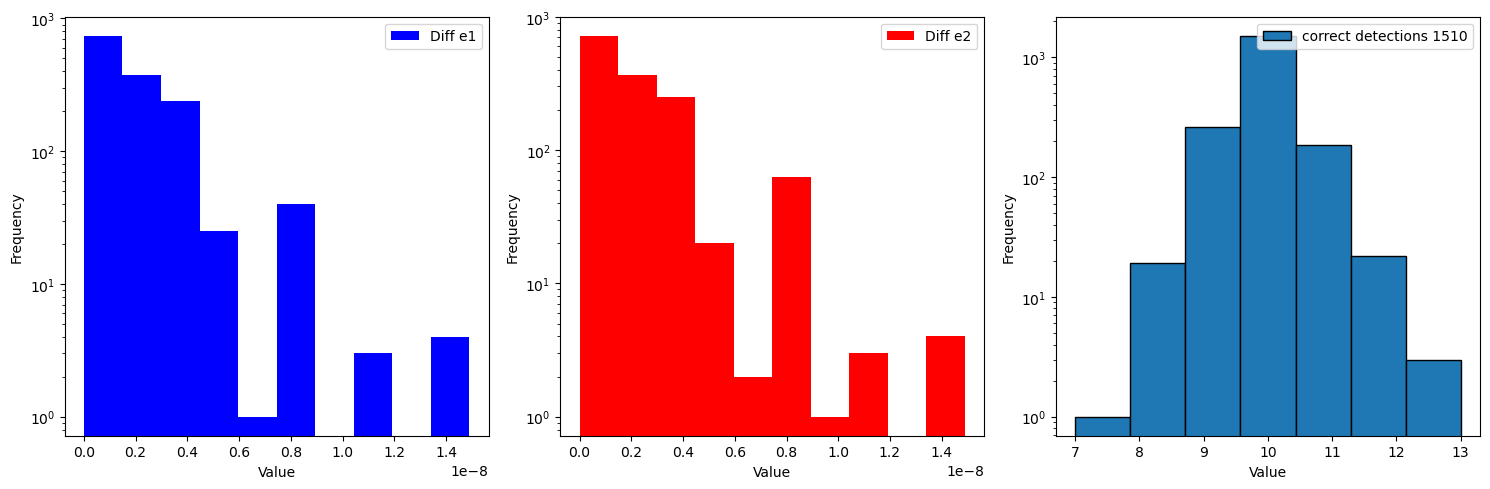

In [9]:
histos(
    diff_e1=pred_avg_e[:, 0] - pred_avg_e[:, 2],
    diff_e2=pred_avg_e[:, 1] - pred_avg_e[:, 3],
    data_gal=gal_detect,
    nb_detected=NB_TOTAL - NB_FAKE_SEG,
    directory=PLOTS_DIR,
    bins=10,
)

# results

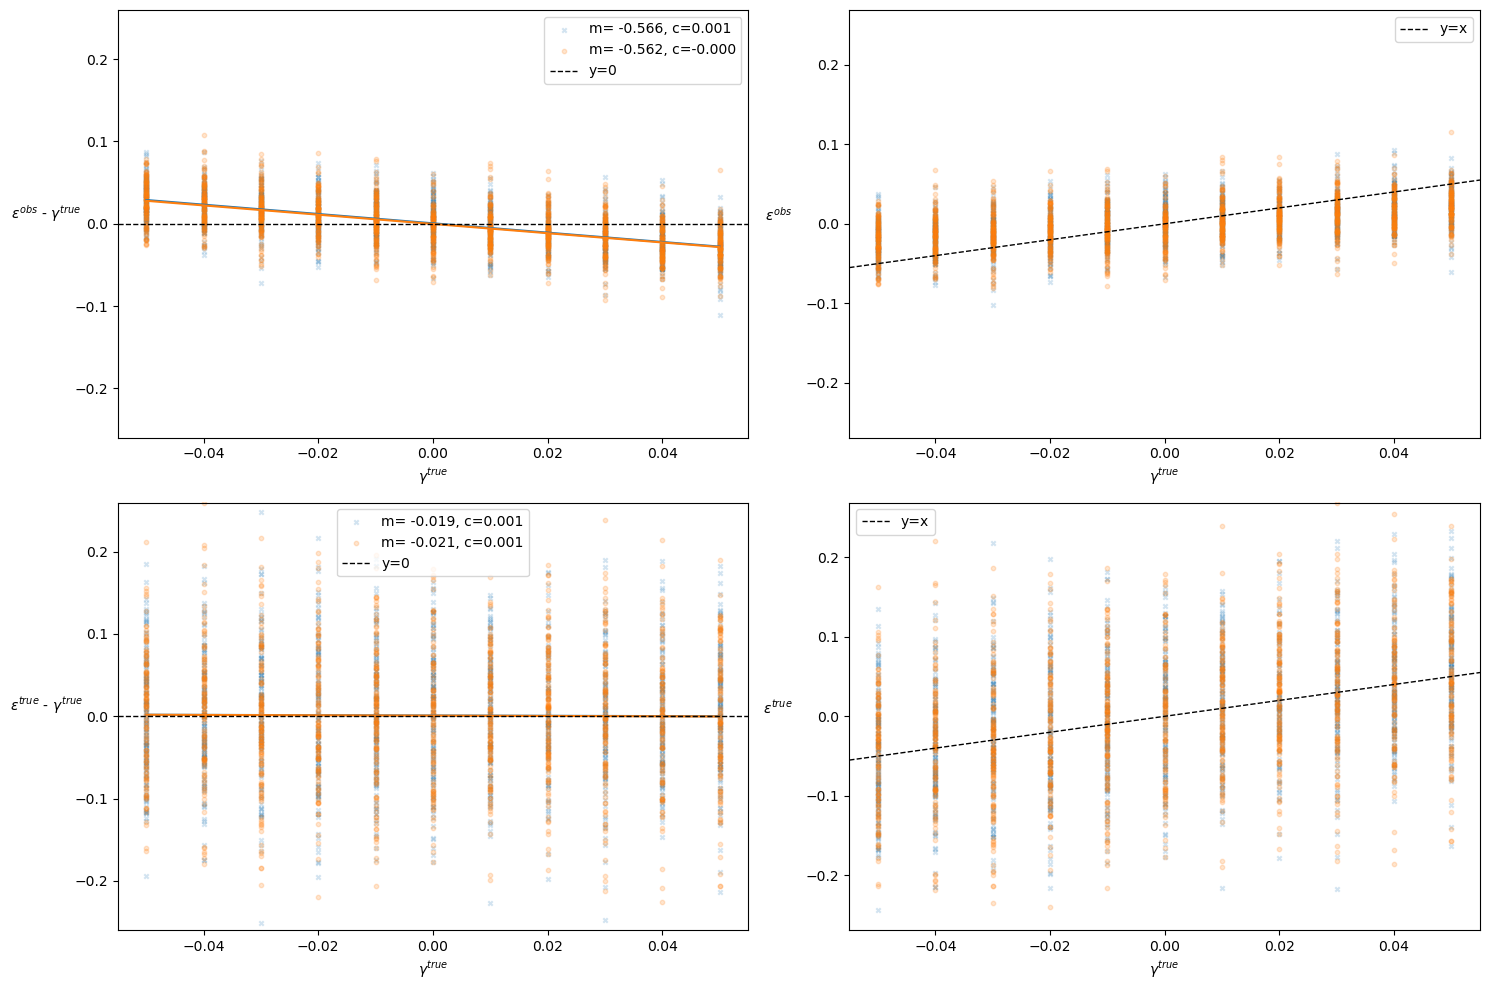

In [10]:
final_results(true_avg_e, pred_avg_e[:, :2], true_shears, PLOTS_DIR / "results.pdf")

# results recons

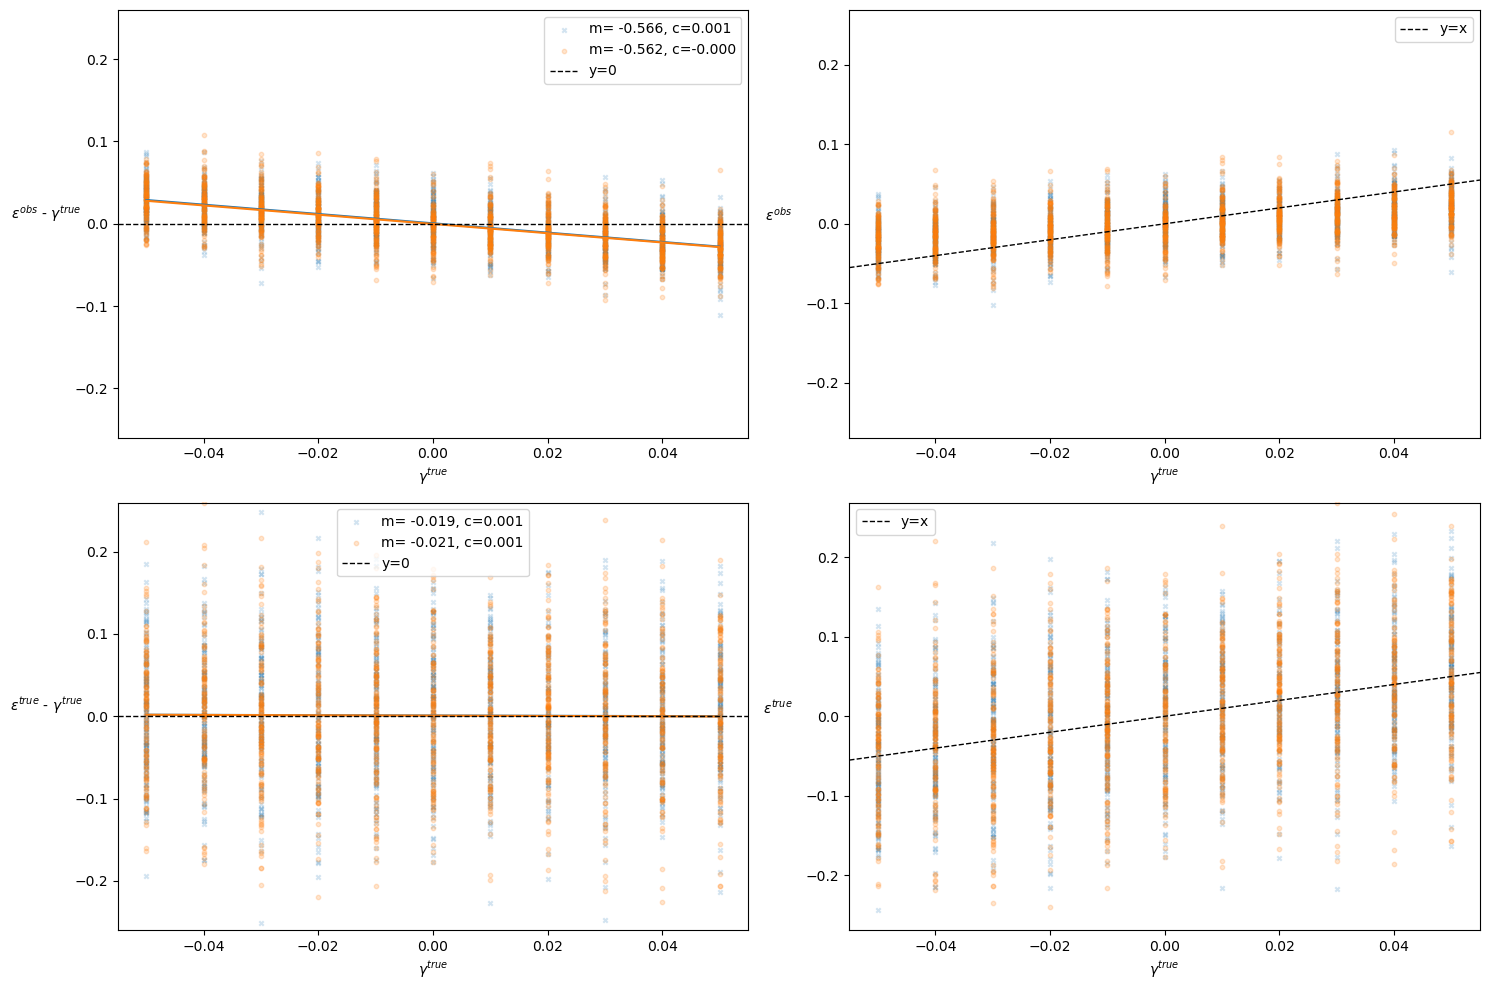

In [11]:
final_results(true_avg_e, pred_avg_e[:, -2:], true_shears, PLOTS_DIR / "results_recons.pdf")